### 시도별 지가와 요양시설 잔여정원 상관관계

본 분석은 '초고령 사회, 서울의 의료·돌봄 인프라는 어디에 더 필요한가?'에서 **땅값이 비싼 지역일수록 요양시설에 남는 자리가 적은가**를 17개 시도 단위로 확인하기 위해 작성되었다. 한국은행(2026)은 전국 시군구 패널(2016~2024)로 '지가가 10% 높을수록 잔여정원 비율이 2.3%p 낮다'고 추정했다(그림 3.2, 별첨 2). 여기서는 같은 변수 정의를 써서 2024년 시도 횡단면에서도 같은 방향의 관계가 보이는지, 그리고 그 관계가 서울 한 곳에 얼마나 기대고 있는지를 점검한다.

### 1. 분석 기준

- 분석 단위: 17개 시도(서울특별시 + 6개 광역시 + 세종 + 9개 도)
- 지가: 국토교통부 표준지공시지가(2024-01-01 공시 기준), **시도 안 표준지의 ㎡당 공시지가 단순평균** — 한국은행 별첨 2의 정의(`단위면적(㎡)당 평균 표준지공시지가`, 로그 변환)와 같다.
- 잔여정원 비율: `(입소 정원 − 현원) ÷ 장기요양 1~2등급 인정자 수 × 100` — 한국은행 시군구 분석의 종속변수, 기존 자치구 분석 6절과 같은 정의
  - 시설: 국민건강보험공단 장기요양기관 시설별 현황(2024-07-16), 입소시설 A01~A05
  - 수요: 국민건강보험공단 노인장기요양보험 등급판정 현황(2024-07-31)
- 보조 지표: 가동률 `현원 ÷ 정원`
- 통계량: 피어슨 상관(ln 지가), 스피어만 순위상관, 단순회귀 기울기(HC1 강건 표준오차)

시설·등급 원자료는 `서울시 자치구별 75세 이상 인구 대비 요양시설 정원/assets`의 파일을 그대로 읽는다(복사하지 않음). 표준지공시지가 원자료(약 58만 필지, 170MB)는 공공데이터포털에서 내려받아 `assets/`에 캐시하며 git에는 올리지 않는다. 집계 결과는 `outputs/`에 저장한다.

In [1]:
from pathlib import Path
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
import statsmodels.formula.api as smf
from IPython.display import display, Markdown
from scipy import stats

pd.set_option("display.max_rows", 50)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

plt.rcParams["font.family"] = ["AppleGothic", "Arial Unicode MS", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False

ASSET_DIR = Path("assets")
OUTPUT_DIR = Path("outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

GU_ANALYSIS_DIR = Path("..") / "서울시 자치구별 75세 이상 인구 대비 요양시설 정원" / "assets"
FACILITY_FILE = GU_ANALYSIS_DIR / "국민건강보험공단_장기요양기관 시설별 현황_20240716.xlsx"
GRADE_FILE = GU_ANALYSIS_DIR / "국민건강보험공단_노인장기요양보험 등급판정 현황_20240731.csv"

# 공공데이터포털 '국토교통부_표준지공시지가'(15004246)의 2024-01-01 이력 파일
LAND_FILE = ASSET_DIR / "국토교통부_표준지공시지가_20240101.csv"
LAND_URL = (
    "https://www.data.go.kr/cmm/cmm/fileDownload.do"
    "?atchFileId=FILE_000000002945598&fileDetailSn=1&insertDataPrcus=N"
)

SIDO_ALIAS = {
    "서울특별시": "서울", "부산광역시": "부산", "대구광역시": "대구", "인천광역시": "인천",
    "광주광역시": "광주", "대전광역시": "대전", "울산광역시": "울산", "세종특별자치시": "세종",
    "경기도": "경기", "강원도": "강원", "강원특별자치도": "강원", "충청북도": "충북", "충청남도": "충남",
    "전라북도": "전북", "전북특별자치도": "전북", "전라남도": "전남",
    "경상북도": "경북", "경상남도": "경남", "제주특별자치도": "제주",
}
PROVINCES = ["경기", "강원", "충북", "충남", "전북", "전남", "경북", "경남", "제주"]
RESIDENTIAL_CODES = ["A01", "A02", "A03", "A04", "A05"]

### 2. 시도별 지가 집계

한국은행 정의대로 표준지의 ㎡당 공시지가를 시도별로 단순평균한다. 단순평균은 극단적으로 비싼 도심 표준지의 영향을 크게 받고, 도 지역은 농지·임야 표준지가 많아 평균이 낮게 나온다. 그래서 두 가지 대안 지표를 함께 계산해 8절에서 결론이 지표 선택에 달려 있지 않은지 확인한다.

- `중위 지가`: 극단값에 덜 민감한 중앙값
- `대지 평균 지가`: 지목이 `대`(건축물을 지을 수 있는 땅)인 표준지만의 평균 — 요양시설이 실제로 들어서는 토지에 가깝다.

In [2]:
if not LAND_FILE.exists():
    ASSET_DIR.mkdir(exist_ok=True)
    with requests.get(LAND_URL, stream=True, timeout=600) as response:
        response.raise_for_status()
        with open(LAND_FILE, "wb") as f:
            for chunk in response.iter_content(chunk_size=1 << 20):
                f.write(chunk)

land = pd.read_csv(
    LAND_FILE, encoding="utf-8-sig", usecols=["시도명", "시군구명", "지목", "공시지가"]
)
land["시도"] = land["시도명"].map(SIDO_ALIAS)
assert land["시도"].notna().all() and land["시도"].nunique() == 17
assert (land["공시지가"] > 0).all()

land_by_sido = land.groupby("시도").agg(
    표준지수=("공시지가", "size"),
    평균_지가=("공시지가", "mean"),
    중위_지가=("공시지가", "median"),
)
land_by_sido["대지_평균_지가"] = land.loc[land["지목"].eq("대")].groupby("시도")["공시지가"].mean()
land_by_sido = land_by_sido.reset_index()
land_by_sido.to_csv(OUTPUT_DIR / "시도별_표준지공시지가_2024.csv", index=False, encoding="utf-8-sig")

print(f"표준지 {len(land):,}필지, 17개 시도")
land_by_sido.sort_values("평균_지가", ascending=False).style.format({
    "표준지수": "{:,.0f}", "평균_지가": "{:,.0f}", "중위_지가": "{:,.0f}", "대지_평균_지가": "{:,.0f}",
}).hide(axis="index")

표준지 580,000필지, 17개 시도


시도,표준지수,평균_지가,중위_지가,대지_평균_지가
서울,"31,044","6,778,948","4,811,000","7,010,890"
부산,"19,680","1,937,491","1,307,000","2,276,190"
인천,"13,070","1,129,430","1,074,000","1,630,965"
대구,"16,799","1,089,394","840,500","1,607,668"
대전,"7,692","926,918","810,600","1,234,650"
경기,"71,227","824,195","236,000","1,618,816"
울산,"9,515","711,527","327,400","1,231,541"
광주,"9,563","709,704","605,800","990,058"
세종,"2,718","351,893","148,200","751,733"
제주,"11,683","286,376","108,300","652,340"


### 3. 시도별 잔여정원 비율 집계

기존 자치구 분석과 같은 방식으로 `일반현황`의 소재지(법정동명이 빈 기관은 상세주소로 보완)와 `입소인원`의 정원·현원을 기관코드로 결합해 시도별로 합친다.

In [3]:
general = pd.read_excel(FACILITY_FILE, sheet_name="일반현황", dtype={"장기요양기관코드": str})
capacity = pd.read_excel(FACILITY_FILE, sheet_name="입소인원", dtype={"장기요양기관코드": str})

region = general["시도 시군구 법정동명"].str.extract(r"^(\S+)")[0]
region_fallback = general["기관별 상세주소"].str.extract(r"^(\S+)")[0]
general["시도"] = region.fillna(region_fallback).map(SIDO_ALIAS)

residential = capacity.loc[capacity["기관유형코드"].isin(RESIDENTIAL_CODES)].merge(
    general[["장기요양기관코드", "시도"]], on="장기요양기관코드", how="inner", validate="many_to_one"
)
assert residential["시도"].notna().all()

facility_by_sido = residential.groupby("시도", as_index=False).agg(
    시설수=("장기요양기관코드", "nunique"), 정원=("정원", "sum"), 현원=("현원", "sum")
)

grade_raw = pd.read_csv(GRADE_FILE, encoding="cp949")
grade_raw.columns = [c.strip() for c in grade_raw.columns]
grade_raw["시도"] = grade_raw["시도"].astype(str).str.strip()
for col in ["1등급", "2등급"]:
    grade_raw[col] = pd.to_numeric(
        grade_raw[col].astype(str).str.replace(",", "", regex=False), errors="coerce"
    )
grade_raw["중증_1_2등급"] = grade_raw["1등급"] + grade_raw["2등급"]
severe_by_sido = grade_raw.groupby("시도", as_index=False)["중증_1_2등급"].sum()

supply = facility_by_sido.merge(severe_by_sido, on="시도", how="inner", validate="one_to_one")
supply["잔여정원"] = supply["정원"] - supply["현원"]
supply["잔여정원_비율"] = supply["잔여정원"] / supply["중증_1_2등급"] * 100
supply["가동률"] = supply["현원"] / supply["정원"] * 100
assert len(supply) == 17

### 4. 결합

In [4]:
sido = supply.merge(land_by_sido, on="시도", how="inner", validate="one_to_one")
assert len(sido) == 17 and not sido.isna().any().any()

for col in ["평균_지가", "중위_지가", "대지_평균_지가"]:
    sido[f"ln_{col}"] = np.log(sido[col])
sido["구분"] = np.where(
    sido["시도"].eq("서울"), "서울", np.where(sido["시도"].isin(PROVINCES), "도", "광역시·세종")
)
sido = sido.sort_values("평균_지가", ascending=False).reset_index(drop=True)
sido.to_csv(OUTPUT_DIR / "시도별_지가_잔여정원.csv", index=False, encoding="utf-8-sig")

display(
    sido[["시도", "구분", "평균_지가", "정원", "현원", "잔여정원", "중증_1_2등급", "잔여정원_비율", "가동률"]]
    .style.format({
        "평균_지가": "{:,.0f}", "정원": "{:,.0f}", "현원": "{:,.0f}", "잔여정원": "{:,.0f}",
        "중증_1_2등급": "{:,.0f}", "잔여정원_비율": "{:.1f}", "가동률": "{:.1f}",
    })
    .background_gradient(subset=["잔여정원_비율"], cmap="Blues")
    .hide(axis="index")
)

시도,구분,평균_지가,정원,현원,잔여정원,중증_1_2등급,잔여정원_비율,가동률
서울,서울,"6,778,948","16,055","14,588","1,467","23,249",6.3,90.9
부산,광역시·세종,"1,937,491","7,071","5,494","1,577","10,025",15.7,77.7
인천,광역시·세종,"1,129,430","20,416","16,738","3,678","9,617",38.2,82.0
대구,광역시·세종,"1,089,394","9,701","8,316","1,385","7,220",19.2,85.7
대전,광역시·세종,"926,918","7,530","6,063","1,467","4,563",32.1,80.5
경기,도,"824,195","88,288","71,369","16,919","38,801",43.6,80.8
울산,광역시·세종,"711,527","2,762","2,076",686,"2,613",26.3,75.2
광주,광역시·세종,"709,704","3,879","3,193",686,"3,775",18.2,82.3
세종,광역시·세종,"351,893",872,687,185,452,40.9,78.8
제주,도,"286,376","3,991","3,174",817,"2,455",33.3,79.5


### 5. 상관분석

지가는 서울이 전남의 약 86배일 만큼 분포가 치우쳐 있어, 한국은행과 같이 로그를 취한 뒤 피어슨 상관과 회귀 기울기를 구한다. 표본이 17개로 작고 서울이 지가 축에서 홀로 떨어져 있으므로, 극단값의 영향을 덜 받는 스피어만 순위상관을 함께 본다.

In [5]:
def correlate(data, y, x="ln_평균_지가"):
    pearson = stats.pearsonr(data[x], data[y])
    spearman = stats.spearmanr(data[x], data[y])
    model = smf.ols(f"{y} ~ {x}", data=data).fit(cov_type="HC1")
    return {
        "n": len(data),
        "피어슨_r": pearson.statistic, "피어슨_p": pearson.pvalue,
        "스피어만_rho": spearman.statistic, "스피어만_p": spearman.pvalue,
        "기울기": model.params[x], "기울기_p": model.pvalues[x],
        "지가10%당_변화(%p)": model.params[x] * np.log(1.1),
    }


main = correlate(sido, "잔여정원_비율")
occupancy = correlate(sido, "가동률")
main_model = smf.ols("잔여정원_비율 ~ ln_평균_지가", data=sido).fit(cov_type="HC1")

result = pd.DataFrame(
    [main, occupancy], index=["잔여정원 비율(%)", "가동률(%)"]
).rename_axis("종속변수")
display(result.style.format({
    "n": "{:.0f}", "피어슨_r": "{:.2f}", "피어슨_p": "{:.3f}", "스피어만_rho": "{:.2f}",
    "스피어만_p": "{:.3f}", "기울기": "{:.2f}", "기울기_p": "{:.3f}", "지가10%당_변화(%p)": "{:.2f}",
}))
display(Markdown(
    f"- ln(평균 지가)와 잔여정원 비율의 피어슨 상관: **r = {main['피어슨_r']:.2f}** (p = {main['피어슨_p']:.3f})\n"
    f"- 스피어만 순위상관: **ρ = {main['스피어만_rho']:.2f}** (p = {main['스피어만_p']:.3f})\n"
    f"- 회귀 기울기: 지가가 10% 높은 시도는 잔여정원 비율이 평균 **{abs(main['지가10%당_변화(%p)']):.2f}%p** 낮다"
))

,n,피어슨_r,피어슨_p,스피어만_rho,스피어만_p,기울기,기울기_p,지가10%당_변화(%p)
종속변수,,,,,,,,
잔여정원 비율(%),17,-0.59,0.013,-0.46,0.063,-5.33,0.002,-0.51
가동률(%),17,0.39,0.122,0.22,0.390,1.20,0.205,0.11


- ln(평균 지가)와 잔여정원 비율의 피어슨 상관: **r = -0.59** (p = 0.013)
- 스피어만 순위상관: **ρ = -0.46** (p = 0.063)
- 회귀 기울기: 지가가 10% 높은 시도는 잔여정원 비율이 평균 **0.51%p** 낮다

### 6. 시각화: 지가와 잔여정원 비율

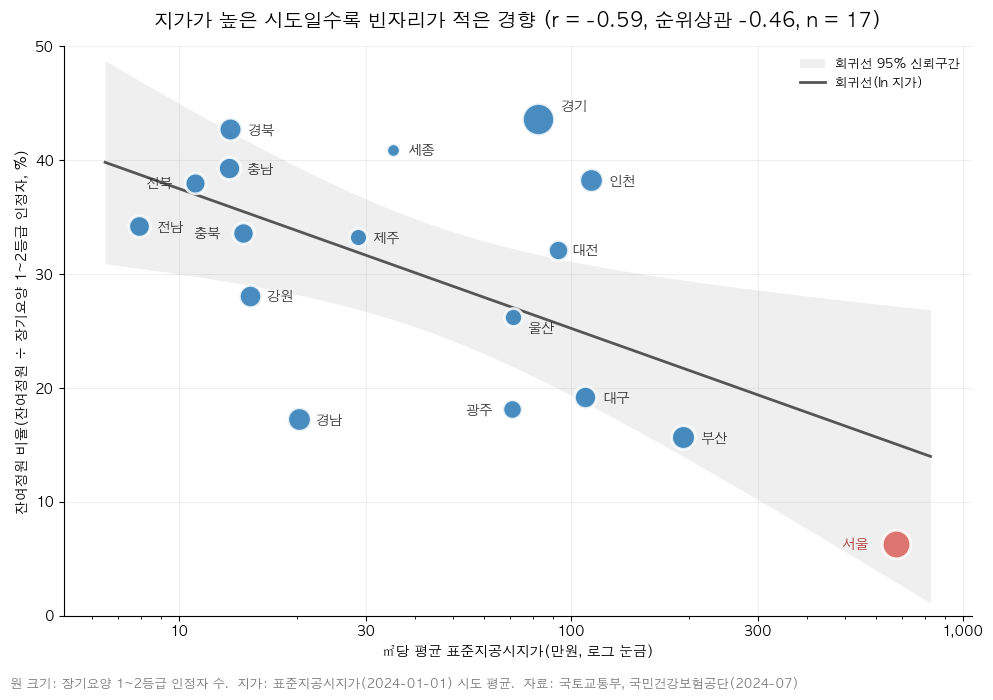

In [6]:
SEOUL_COLOR = "#D95F59"
OTHER_COLOR = "#2878B5"
LABEL_OFFSET = {
    "서울": (-40, -4), "부산": (12, -4), "인천": (12, -4), "대구": (12, -4), "대전": (10, -4),
    "경기": (16, 6), "울산": (10, -12), "광주": (-34, -4), "세종": (10, -4), "제주": (10, -4),
    "경남": (12, -4), "강원": (12, -4), "충북": (-36, -4), "경북": (12, -4), "충남": (12, -4),
    "전북": (-36, -4), "전남": (12, -4),
}

x_grid = np.linspace(sido["ln_평균_지가"].min() - 0.2, sido["ln_평균_지가"].max() + 0.2, 200)
ols = smf.ols("잔여정원_비율 ~ ln_평균_지가", data=sido).fit()
band = ols.get_prediction(pd.DataFrame({"ln_평균_지가": x_grid})).summary_frame(alpha=0.05)

fig, ax = plt.subplots(figsize=(10, 7))
ax.fill_between(np.exp(x_grid) / 1e4, band["mean_ci_lower"], band["mean_ci_upper"],
                color="#999999", alpha=0.15, linewidth=0, label="회귀선 95% 신뢰구간")
ax.plot(np.exp(x_grid) / 1e4, band["mean"], color="#555555", linewidth=2, label="회귀선(ln 지가)")
for _, row in sido.iterrows():
    is_seoul = row["시도"] == "서울"
    ax.scatter(row["평균_지가"] / 1e4, row["잔여정원_비율"], s=40 + np.sqrt(row["중증_1_2등급"]) * 2.5,
               color=SEOUL_COLOR if is_seoul else OTHER_COLOR, alpha=0.85,
               edgecolor="white", linewidth=2, zorder=3)
    ax.annotate(row["시도"], (row["평균_지가"] / 1e4, row["잔여정원_비율"]),
                xytext=LABEL_OFFSET.get(row["시도"], (8, 2)), textcoords="offset points",
                fontsize=10, color="#B03A35" if is_seoul else "#333333",
                fontweight="bold" if is_seoul else "normal")
ax.set_xscale("log")
ax.set_xticks([10, 30, 100, 300, 1000])
ax.set_xticklabels(["10", "30", "100", "300", "1,000"])
ax.set_xlabel("㎡당 평균 표준지공시지가(만원, 로그 눈금)")
ax.set_ylabel("잔여정원 비율(잔여정원 ÷ 장기요양 1~2등급 인정자, %)")
ax.set_ylim(0, 50)
ax.grid(alpha=0.2)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(loc="upper right", frameon=False, fontsize=9)
ax.set_title(
    f"지가가 높은 시도일수록 빈자리가 적은 경향 (r = {main['피어슨_r']:.2f}, 순위상관 {main['스피어만_rho']:.2f}, n = 17)",
    fontsize=14, pad=14,
)
fig.text(0.01, 0.01,
         "원 크기: 장기요양 1~2등급 인정자 수.  지가: 표준지공시지가(2024-01-01) 시도 평균.  "
         "자료: 국토교통부, 국민건강보험공단(2024-07)",
         fontsize=9, color="#777777")
plt.tight_layout(rect=[0, 0.03, 1, 1])
fig.savefig(OUTPUT_DIR / "시도별_지가_잔여정원_산점도.png", dpi=200, bbox_inches="tight")
plt.show()

### 7. 시각화: 지가 순위와 잔여정원 비율 비교

산점도의 로그 눈금은 지가 격차를 압축해서 보여준다. 실제 수준 차이와 두 변수의 순서를 함께 보기 위해 지가 순으로 나란히 배열한다.

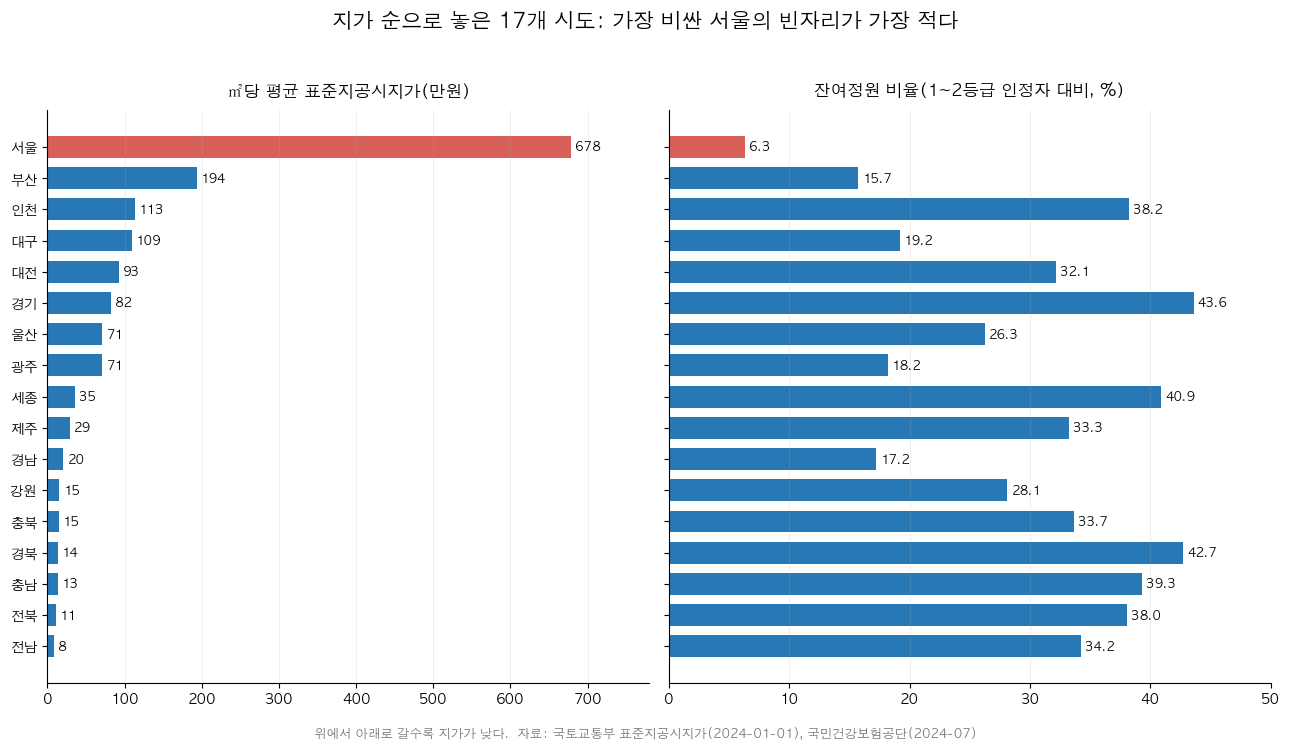

In [7]:
order = sido.sort_values("평균_지가")
colors = [SEOUL_COLOR if s == "서울" else OTHER_COLOR for s in order["시도"]]

fig, (ax_land, ax_vac) = plt.subplots(1, 2, figsize=(13, 7.5), sharey=True)
bars = ax_land.barh(order["시도"], order["평균_지가"] / 1e4, color=colors, height=0.7)
ax_land.bar_label(bars, labels=[f"{v / 1e4:,.0f}" for v in order["평균_지가"]], padding=3, fontsize=9)
ax_land.set_title("㎡당 평균 표준지공시지가(만원)", fontsize=12, pad=10)
ax_land.set_xlim(0, order["평균_지가"].max() / 1e4 * 1.15)

bars = ax_vac.barh(order["시도"], order["잔여정원_비율"], color=colors, height=0.7)
ax_vac.bar_label(bars, labels=[f"{v:.1f}" for v in order["잔여정원_비율"]], padding=3, fontsize=9)
ax_vac.set_title("잔여정원 비율(1~2등급 인정자 대비, %)", fontsize=12, pad=10)
ax_vac.set_xlim(0, 50)

for ax in (ax_land, ax_vac):
    ax.grid(axis="x", alpha=0.2)
    ax.spines[["top", "right"]].set_visible(False)
fig.suptitle("지가 순으로 놓은 17개 시도: 가장 비싼 서울의 빈자리가 가장 적다", fontsize=15, y=0.98)
fig.text(0.5, 0.01, "위에서 아래로 갈수록 지가가 낮다.  자료: 국토교통부 표준지공시지가(2024-01-01), 국민건강보험공단(2024-07)",
         ha="center", fontsize=9, color="#777777")
plt.tight_layout(rect=[0, 0.03, 1, 0.95])
fig.savefig(OUTPUT_DIR / "시도별_지가_잔여정원_막대.png", dpi=200, bbox_inches="tight")
plt.show()

### 8. 강건성 점검

표본이 17개뿐이고 서울의 지가가 2위 부산의 3.5배에 달해, 서울 한 점이 상관을 만들어 낼 수 있다. 다음을 바꿔 가며 상관이 유지되는지 본다.

- 지가 지표: 평균 / 중위 / 대지 평균
- 표본: 17개 시도 전체 / 서울 제외 16개 / 서울 + 9개 도(질문의 '서울과 도' 비교)

In [8]:
samples = {
    "17개 시도": sido,
    "서울 제외(16)": sido.loc[sido["시도"].ne("서울")],
    "서울 + 9개 도(10)": sido.loc[sido["시도"].isin(["서울", *PROVINCES])],
}
measures = {"평균 지가": "ln_평균_지가", "중위 지가": "ln_중위_지가", "대지 평균 지가": "ln_대지_평균_지가"}

robust = pd.DataFrame([
    {"표본": s_name, "지가 지표": m_name, **correlate(data, "잔여정원_비율", x=m_col)}
    for s_name, data in samples.items() for m_name, m_col in measures.items()
])
robust.to_csv(OUTPUT_DIR / "시도별_강건성.csv", index=False, encoding="utf-8-sig")

loo = pd.DataFrame([
    {"제외 시도": name, **correlate(sido.loc[sido["시도"].ne(name)], "잔여정원_비율")}
    for name in sido["시도"]
])

display(
    robust[["표본", "지가 지표", "n", "피어슨_r", "피어슨_p", "스피어만_rho", "스피어만_p", "지가10%당_변화(%p)"]]
    .style.format({"n": "{:.0f}", "피어슨_r": "{:.2f}", "피어슨_p": "{:.3f}", "스피어만_rho": "{:.2f}",
                   "스피어만_p": "{:.3f}", "지가10%당_변화(%p)": "{:.2f}"})
    .hide(axis="index")
)
display(Markdown(
    f"- 한 시도씩 빼고 다시 계산한 피어슨 r의 범위: **{loo['피어슨_r'].min():.2f} ~ {loo['피어슨_r'].max():.2f}** "
    f"(가장 약해지는 경우: {loo.loc[loo['피어슨_r'].idxmax(), '제외 시도']} 제외)"
))

표본,지가 지표,n,피어슨_r,피어슨_p,스피어만_rho,스피어만_p,지가10%당_변화(%p)
17개 시도,평균 지가,17,-0.59,0.013,-0.46,0.063,-0.51
17개 시도,중위 지가,17,-0.55,0.021,-0.52,0.033,-0.32
17개 시도,대지 평균 지가,17,-0.57,0.017,-0.41,0.103,-0.66
서울 제외(16),평균 지가,16,-0.39,0.134,-0.35,0.180,-0.35
서울 제외(16),중위 지가,16,-0.39,0.131,-0.42,0.102,-0.22
서울 제외(16),대지 평균 지가,16,-0.35,0.188,-0.29,0.274,-0.43
서울 + 9개 도(10),평균 지가,10,-0.61,0.061,-0.41,0.244,-0.52
서울 + 9개 도(10),중위 지가,10,-0.61,0.061,-0.38,0.276,-0.39
서울 + 9개 도(10),대지 평균 지가,10,-0.59,0.071,-0.41,0.244,-0.65


- 한 시도씩 빼고 다시 계산한 피어슨 r의 범위: **-0.68 ~ -0.39** (가장 약해지는 경우: 서울 제외)

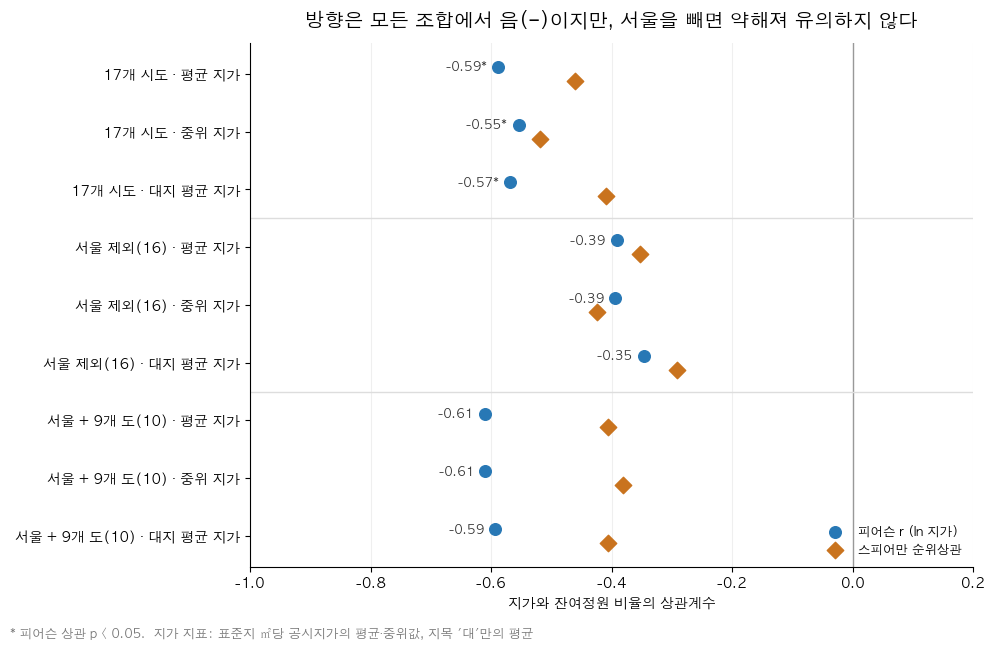

In [9]:
plot = robust.copy()
plot["label"] = plot["표본"] + " · " + plot["지가 지표"]
plot = plot.iloc[::-1].reset_index(drop=True)

fig, ax = plt.subplots(figsize=(10, 6.5))
y = np.arange(len(plot))
ax.axvline(0, color="#999999", linewidth=1)
ax.scatter(plot["피어슨_r"], y + 0.12, s=70, color=OTHER_COLOR, zorder=3, label="피어슨 r (ln 지가)")
ax.scatter(plot["스피어만_rho"], y - 0.12, s=70, color="#C9731E", marker="D", zorder=3, label="스피어만 순위상관")
for i, row in plot.iterrows():
    sig = row["피어슨_p"] < 0.05
    ax.annotate(f"{row['피어슨_r']:.2f}{'*' if sig else ''}", (row["피어슨_r"], i + 0.12),
                xytext=(-8, 0), textcoords="offset points", ha="right", va="center", fontsize=9, color="#333333")
ax.set_yticks(y)
ax.set_yticklabels(plot["label"])
for boundary in (2.5, 5.5):
    ax.axhline(boundary, color="#DDDDDD", linewidth=1)
ax.set_xlim(-1, 0.2)
ax.set_xlabel("지가와 잔여정원 비율의 상관계수")
ax.grid(axis="x", alpha=0.2)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(loc="lower right", frameon=False, fontsize=9)
ax.set_title("방향은 모든 조합에서 음(−)이지만, 서울을 빼면 약해져 유의하지 않다", fontsize=14, pad=12)
fig.text(0.01, 0.01, "* 피어슨 상관 p < 0.05.  지가 지표: 표준지 ㎡당 공시지가의 평균·중위값, 지목 '대'만의 평균",
         fontsize=9, color="#777777")
plt.tight_layout(rect=[0, 0.03, 1, 1])
fig.savefig(OUTPUT_DIR / "시도별_강건성.png", dpi=200, bbox_inches="tight")
plt.show()

### 9. 해석

In [10]:
seoul = sido.set_index("시도").loc["서울"]
busan = sido.set_index("시도").loc["부산"]
no_seoul = robust.set_index(["표본", "지가 지표"]).loc[("서울 제외(16)", "평균 지가")]
province = robust.set_index(["표본", "지가 지표"]).loc[("서울 + 9개 도(10)", "평균 지가")]

display(Markdown(f"""
- 17개 시도에서 ln(평균 지가)와 잔여정원 비율의 피어슨 상관은 **{main['피어슨_r']:.2f}**(p = {main['피어슨_p']:.3f}), 스피어만 순위상관은 **{main['스피어만_rho']:.2f}**(p = {main['스피어만_p']:.3f})다. 지가가 높은 시도일수록 중증 수요 대비 빈자리가 적은 경향이 있고, 회귀 기울기로는 지가가 10% 높을 때 잔여정원 비율이 약 {abs(main['지가10%당_변화(%p)']):.1f}%p 낮다.
- 서울은 ㎡당 평균 지가가 {seoul['평균_지가'] / 1e4:,.0f}만원으로 2위 부산({busan['평균_지가'] / 1e4:,.0f}만원)의 {seoul['평균_지가'] / busan['평균_지가']:.1f}배이고, 잔여정원 비율은 {seoul['잔여정원_비율']:.1f}%로 17개 시도 중 가장 낮다. 가동률도 {seoul['가동률']:.1f}%로 가장 높다.
- 다만 이 관계는 서울에 크게 기댄다. 서울을 빼면 피어슨 r은 {no_seoul['피어슨_r']:.2f}(p = {no_seoul['피어슨_p']:.2f})로 약해져 유의하지 않다. 서울과 9개 도만 비교하면 r = {province['피어슨_r']:.2f}(p = {province['피어슨_p']:.2f})다. 지가 지표를 중위값이나 대지 평균으로 바꿔도 방향은 같다.
- 지가 2위 부산({busan['잔여정원_비율']:.1f}%)과 대구·광주·경남처럼 빈자리가 적은 지역도 있는 반면, 지가가 중간인 경기·인천은 빈자리가 많다. 시도 단위의 지가 차이만으로 빈자리 차이를 설명하기는 어렵고, 서울이 '가장 비싸고 가장 빠듯한' 극단에 있다는 점이 두드러진다.
"""))


- 17개 시도에서 ln(평균 지가)와 잔여정원 비율의 피어슨 상관은 **-0.59**(p = 0.013), 스피어만 순위상관은 **-0.46**(p = 0.063)다. 지가가 높은 시도일수록 중증 수요 대비 빈자리가 적은 경향이 있고, 회귀 기울기로는 지가가 10% 높을 때 잔여정원 비율이 약 0.5%p 낮다.
- 서울은 ㎡당 평균 지가가 678만원으로 2위 부산(194만원)의 3.5배이고, 잔여정원 비율은 6.3%로 17개 시도 중 가장 낮다. 가동률도 90.9%로 가장 높다.
- 다만 이 관계는 서울에 크게 기댄다. 서울을 빼면 피어슨 r은 -0.39(p = 0.13)로 약해져 유의하지 않다. 서울과 9개 도만 비교하면 r = -0.61(p = 0.06)다. 지가 지표를 중위값이나 대지 평균으로 바꿔도 방향은 같다.
- 지가 2위 부산(15.7%)과 대구·광주·경남처럼 빈자리가 적은 지역도 있는 반면, 지가가 중간인 경기·인천은 빈자리가 많다. 시도 단위의 지가 차이만으로 빈자리 차이를 설명하기는 어렵고, 서울이 '가장 비싸고 가장 빠듯한' 극단에 있다는 점이 두드러진다.


### 해석상 주의

- **횡단면 상관이지 인과가 아니다.** 지가가 높은 지역은 인구 밀도·소득·의료 인프라도 함께 높다. 한국은행의 −22.8(지가 10%당 −2.3%p)은 시군구 고정효과·연도 고정효과와 통제변수를 넣은 공간패널모형의 *지역 내 시간 변화* 효과라서, 본 분석의 단순 횡단면 기울기와 수치를 직접 견줄 수 없다. 본 분석은 같은 방향의 관계가 2024년 시도 비교에서도 보이는지만 확인한다.
- **시도는 17개뿐이다.** 서울 한 점의 영향이 크므로(8절) '시도 단위에서 지가와 빈자리가 강하게 연결된다'고 쓰기보다는 '가장 비싼 서울이 가장 빠듯하다'는 사실을 전달하는 데 쓰는 것이 안전하다. 지역 안 비교는 서울 25개 자치구 분석(별도 폴더)을 함께 본다.
- **평균 지가는 토지 구성의 영향을 받는다.** 도 지역은 농지·임야 표준지가 많아 평균이 낮다. 대지만의 평균으로 바꿔도 결론의 방향은 같다(8절).
- 잔여정원 비율의 분모(1~2등급 인정자)는 한국은행 시군구 분석의 대리지표이며, 생애말기 고령인구와 수준이 다르다.

In [11]:
# 핵심 수치 검증
assert sido.iloc[0]["시도"] == "서울"
assert sido.sort_values("잔여정원_비율").iloc[0]["시도"] == "서울"
assert round(seoul["잔여정원_비율"], 1) == 6.3
assert round(main["피어슨_r"], 2) == -0.59 and main["피어슨_p"] < 0.05
assert round(main["스피어만_rho"], 2) == -0.46
assert round(no_seoul["피어슨_r"], 2) == -0.39 and no_seoul["피어슨_p"] > 0.05
assert (robust["피어슨_r"] < 0).all() and (robust["스피어만_rho"] < 0).all()
print("검증 통과")

검증 통과


### 출처

- 국토교통부_표준지공시지가(2024-01-01): https://www.data.go.kr/data/15004246/fileData.do (이력 파일 `국토교통부_표준지공시지가_20240101`)
- 국민건강보험공단_장기요양기관 시설별 현황: https://www.data.go.kr/data/15124763/fileData.do
- 국민건강보험공단_노인장기요양보험 등급판정 현황: https://www.data.go.kr/data/3051421/fileData.do
- 한국은행 이슈노트 [제2026-5호] 초고령사회와 생애말기 필수산업의 활성화 (그림 3.2, 별첨 2)